# 06: Turnout conditional-independence check (supplementary)

**Context.** Bozorgmanesh & Rydén (2025, *Int. J. Med. Inform.*, Appendix A) assume travel time to scene is conditionally independent of preparation time given priority, time of alarm and start/end locations. Our turnout (`response_dttm - dispatch_dttm`) is the analogue of preparation time. We do **not** observe the ambulance's start location, so we can only condition on incident location: this is a weaker, analogous check in different data, **not a test of PreSim's assumption**.

Turnout is not a dispatch-time feature; it is used only for this check. The main model and all earlier results are unchanged.

**Data.** Cleaned ambulance rows (R1–R7) received Jan–Sep 2025 (train + valid). The test period (Oct–Dec) is not used anywhere. Z = the Stage 3 feature set. 5-fold GroupKFold by ISO week of `received_dttm`; all predictions are out-of-fold. Confidence intervals resample calendar days (1000 resamples, seed 0).

All logic lives in `src/turnout_ci.py`; this notebook only calls it.

## Pre-specified thresholds (written before results)

"Practically negligible" = |partial correlation| < 0.05 **AND** OOF MAE gain from adding turnout < 2 s.

- *partial correlation* = point estimate of the Pearson correlation of the OOF residuals r_Y (log1p travel time ~ Z) and r_X (log1p turnout ~ Z).
- *MAE gain* = MAE(Stage 3 point model without turnout) − MAE(with turnout), OOF, point estimate.
- Large n makes tiny effects statistically significant; these thresholds, not p-values, decide the conclusion.
- Part D (recording-artefact checks) has no MAE comparison, so its verdicts use the correlation criterion only.

Upper turnout cutoffs (99th and 99.9th percentiles) are a sensitivity analysis, not a choice.

In [1]:
import sys
from pathlib import Path

# The notebook runs from notebooks/; make the project root importable.
sys.path.insert(0, str(Path.cwd().parent))

from IPython.display import Image
from src import turnout_ci

## Parts A–E

Runs everything and writes `reports/stage7_turnout_ci.txt` (about 5 minutes: ~90 LightGBM fits).


Stage 7 (supplementary): conditional independence of travel time and turnout given Z
data: cleaned ambulance rows (R1-R7), received Jan-Sep 2025 (train + valid); test period not used
rows: 75,209   calendar days: 273   ISO weeks: 40
Z (Stage 3 features): ['lat', 'lon', 'als_unit', 'unit_sequence_in_call_dispatch', 'hour', 'day_of_week', 'workload_60m', 'original_priority_cat', 'station_area', 'battalion', 'unit_type']
turnout_s = response_dttm - dispatch_dttm (not a dispatch-time feature; used only for this check)
folds: 5-fold GroupKFold, groups = ISO week of received_dttm; all predictions OOF
bootstrap: 1000 resamples of calendar days, seed 0

pre-specified thresholds:
"Practically negligible" = |partial correlation| < 0.05 AND OOF MAE gain from adding turnout < 2 s.
partial correlation = point estimate of the Pearson correlation of the OOF residuals r_Y, r_X (log1p scale); MAE gain = MAE(without turnout) - MAE(with turnout), OOF, point estimate.
Large n makes tiny effects statistic

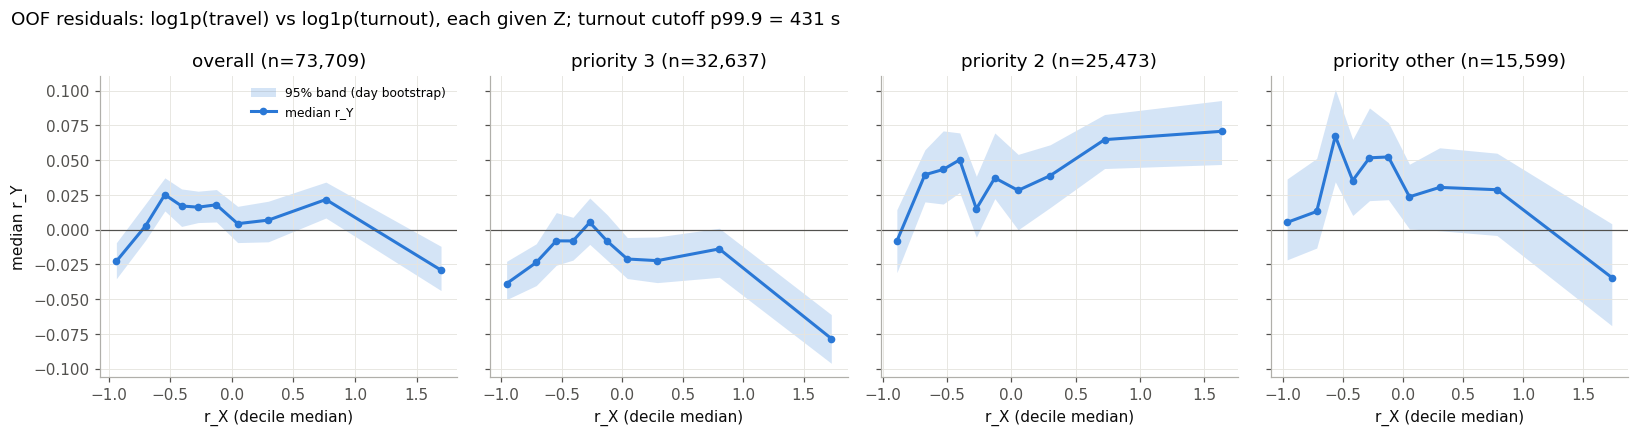

In [2]:
turnout_ci.main()

## Part E figure: median r_Y by decile of r_X (cutoff p99.9)

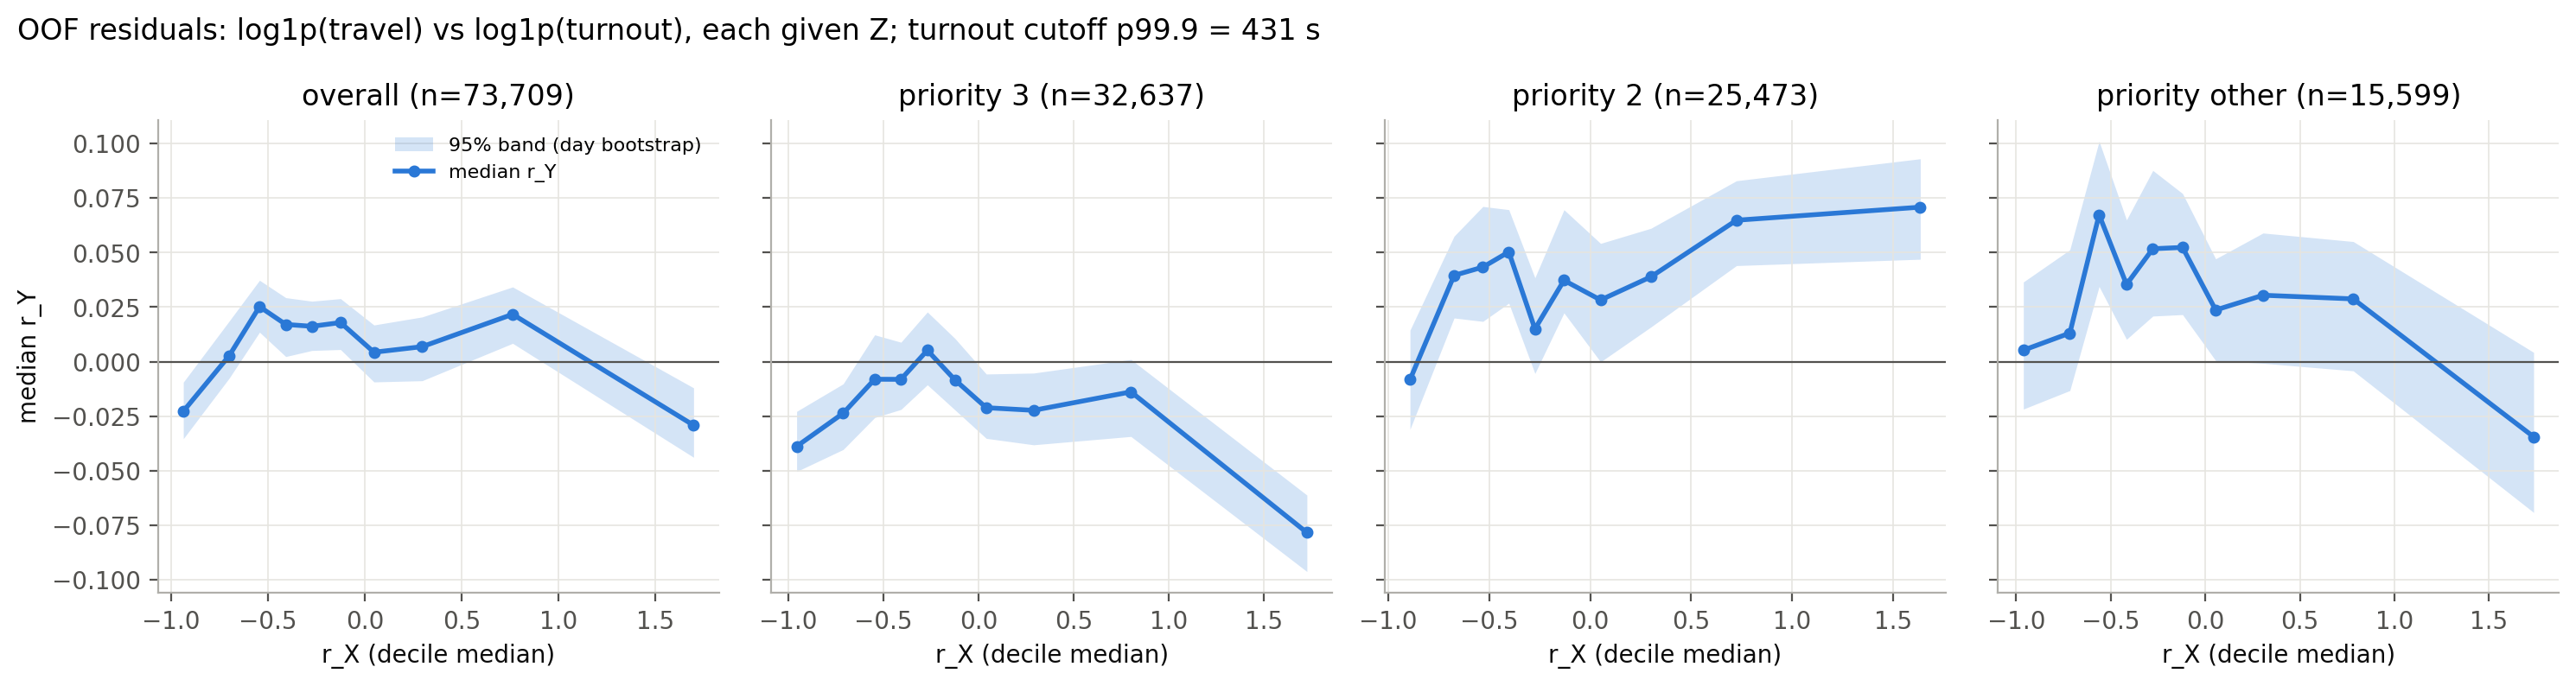

In [3]:
Image(filename=str(turnout_ci.FIG_DIR / turnout_ci.FIG_NAME))